# 06 · Simulación de producción

El modelo no recibe tráfico real, así que se simula con las reseñas **posteriores a la fecha de corte del entrenamiento** del champion (el hold-out temporal del PSet #3 y, si la ingesta trajo reseñas nuevas, también esas).

- **Lote = una semana** (lunes a domingo): el ritmo de la ingesta (Kestra, lunes 06:00) y de la reunión de atención al cliente. Las semanas con menos de 150 reseñas se unen a la siguiente; si quedan menos de 8 semanas, el período se divide en 10 tramos consecutivos de igual tamaño (se informa abajo cuál criterio se usó).
- **Horizonte:** el target de un lote (la calificación confirmada) se usa **un lote después** de la predicción. En el lote *t* se puntúa *t* y se evalúa *t − 1*.
- **Deriva inducida** en los últimos 5 lotes (`src/simulacion.py::inducir_deriva`, semilla 42):
  1. **Recorte de texto:** el 60 % de las reseñas con más de 3 palabras se recortan a sus 3 primeras palabras; se recalculan `n_palabras`, `log_n_palabras` y `n_neg_lexico`. Las estrellas (target) no cambian. Simula que la fuente empieza a entregar solo el inicio del comentario: cambia la distribución de la longitud y la relación entre el texto visible y el target.
  2. **Banco nuevo:** el 3 % de las filas pasan a «Banco Internacional», una entidad que el modelo no conoce. La API las rechaza con 422 (categoría no permitida).

Este notebook lee lo que dejó el flujo `produccion_lotes` en Snowflake; se ejecuta después de la simulación.

In [1]:
import json, mlflow, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.datos import leer_sql, cargar_obt
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 180)
FIG = "/work/docs/figs/"
lotes = leer_sql(f"SELECT * FROM {C.T_LOTES}")
lotes["fecha_resena"] = pd.to_datetime(lotes["fecha_resena"])
corte = pd.to_datetime(lotes["fecha_corte_entrenamiento"].iloc[0])
print("Fecha de corte del entrenamiento:", corte, "| reseñas simuladas:", len(lotes), "| lotes:", lotes["lote_id"].nunique())

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Fecha de corte del entrenamiento: 2026-08-25 20:47:13 | reseñas simuladas: 4801 | lotes: 13


## 1. Lotes construidos

In [2]:
resumen = lotes.groupby("lote_id").agg(inicio=("periodo_inicio","min"), fin=("periodo_fin","max"), n=("review_id","size"),
    pct_negativa=("es_negativa","mean"), con_deriva=("con_deriva","max"), recortadas=("alterado_texto","sum"),
    banco_nuevo=("alterado_banco","sum"), target_disponible=("fecha_target_disponible","max"))
resumen["pct_negativa"] = (resumen["pct_negativa"]*100).round(1)
resumen

,inicio,fin,n,pct_negativa,con_deriva,recortadas,banco_nuevo,target_disponible
lote_id,,,,,,,,
1,2026-08-25,2026-08-30,232,26.3,False,0,0,2026-09-06
2,2026-08-31,2026-09-06,447,38.3,False,0,0,2026-09-13
3,2026-09-07,2026-09-13,429,32.9,False,0,0,2026-09-20
4,2026-09-14,2026-09-20,501,31.3,False,0,0,2026-09-27
5,2026-09-21,2026-09-27,347,38.0,False,0,0,2026-10-04
6,2026-09-28,2026-10-04,346,32.1,False,0,0,2026-10-11
7,2026-10-05,2026-10-11,301,30.2,False,0,0,2026-10-18
8,2026-10-12,2026-10-18,334,35.3,False,0,0,2026-10-25
9,2026-10-19,2026-10-25,323,35.3,True,96,11,2026-11-01


In [3]:
# Verificaciones: (1) todo es posterior al corte, (2) ninguna reseña simulada estuvo en el entrenamiento,
# (3) los lotes no se solapan en el tiempo
from src.pipeline import split_temporal, agregar_features
from src.simulacion import cargar_snapshot
snap, origen = cargar_snapshot()
train, _ = split_temporal(agregar_features(snap), 0.2)
print("1) mínimo de fecha simulada > corte:", lotes["fecha_resena"].min() > corte)
print("2) reseñas simuladas que estaban en el entrenamiento:", lotes["review_id"].isin(train["review_id"]).sum())
lim = lotes.groupby("lote_id")["fecha_resena"].agg(["min","max"])
print("3) lotes sin solape:", bool((lim["min"].iloc[1:].values >= lim["max"].iloc[:-1].values).all()))
print("Origen del corte:", origen)

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


1) mínimo de fecha simulada > corte: True


2) reseñas simuladas que estaban en el entrenamiento: 2
3) lotes sin solape: True
Origen del corte: PSET2_DB.OBT.OBT_RESENAS_SNAP_PSET3


## 2. Qué se alteró en los lotes con deriva

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Reseñas recortadas: 617 (5 lotes). Ejemplos:


,lote_id,original,comentario_limpio,es_negativa
312,11,Desde el 3 de Agosto en mi Honor X6a plus no r...,Desde el 3,1
160,10,de uso fácil y rápido agrego que deberían mejo...,de uso fácil,0
223,10,"Es una porquería, solo pasa colapsada.","Es una porquería,",1
429,12,"Rápida y facil de usar, excelente app.",Rápida y facil,0
23,9,"qué traman con eso,mí cuenta dél banco no es p...",qué traman con,0
47,9,Me ha tomado como 20 fotos y no avanza de ese ...,Me ha tomado,0


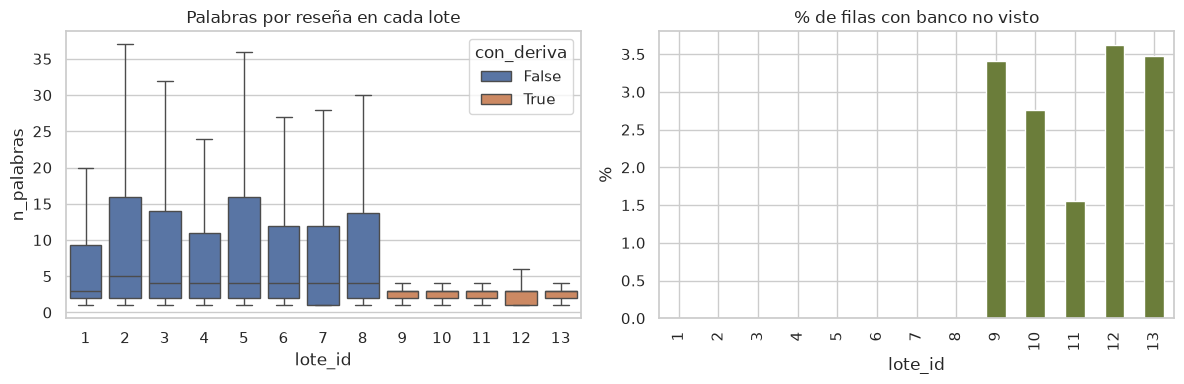

In [4]:
obt = cargar_obt()[["review_id","comentario_limpio","n_palabras"]].rename(columns={"comentario_limpio":"original","n_palabras":"n_palabras_original"})
alt_ = lotes[lotes["alterado_texto"]].merge(obt, on="review_id")
print(f"Reseñas recortadas: {len(alt_)} ({alt_['lote_id'].nunique()} lotes). Ejemplos:")
display(alt_.sample(6, random_state=1)[["lote_id","original","comentario_limpio","es_negativa"]])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=lotes, x="lote_id", y="n_palabras", hue="con_deriva", ax=ax[0], showfliers=False)
ax[0].set_title("Palabras por reseña en cada lote")
b = lotes.groupby("lote_id")["banco"].apply(lambda s: (s == C.DRIFT_BANCO_NUEVO).mean()*100)
b.plot.bar(ax=ax[1], color="#6b7d3a"); ax[1].set_title("% de filas con banco no visto"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.savefig(FIG+"deriva_inducida.png", dpi=150); plt.show()

## 3. Predicciones registradas

In [5]:
pred = leer_sql(f"SELECT lote_id, version_modelo, decision, respaldo, latencia_ms FROM {C.T_PREDICCIONES}")
sol = leer_sql(f"SELECT lote_id, estado_http FROM {C.T_SOLICITUDES} WHERE ruta = '/predecir'")
t = pred.groupby("lote_id").agg(predicciones=("decision","size"), version=("version_modelo", lambda s: ", ".join(sorted(set(map(str, s))))),
     tasa_priorizar=("decision", lambda s: (s=="priorizar").mean()), pct_respaldo=("respaldo","mean"),
     latencia_p95=("latencia_ms", lambda s: np.percentile(s, 95)))
t["rechazadas_422"] = sol[sol["estado_http"]==422].groupby("lote_id").size()
t.fillna({"rechazadas_422": 0}).round(3)

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


,predicciones,version,tasa_priorizar,pct_respaldo,latencia_p95,rechazadas_422
lote_id,,,,,,
1.0,232,1,0.336,0.0,57.678,0.0
2.0,447,1,0.456,0.0,41.305,0.0
3.0,429,1,0.420,0.0,34.491,0.0
4.0,501,1,0.395,0.0,33.121,0.0
5.0,347,1,0.450,0.0,43.187,0.0
6.0,346,1,0.422,0.0,37.475,0.0
7.0,301,1,0.392,0.0,41.031,0.0
8.0,334,1,0.434,0.0,40.244,0.0
9.0,312,1,0.378,0.0,29.071,11.0


## 4. Trazabilidad de una predicción

Una fila de PREDICCIONES → versión y `run_id` del modelo → parámetros del run en MLflow (snapshot de la OBT, hash del dataset, tabla de origen) → tablas Gold de las que Spark construyó la OBT.

In [6]:
mlflow.set_tracking_uri(C.MLFLOW_URI); cli = mlflow.MlflowClient()
p = leer_sql(f"SELECT * FROM {C.T_PREDICCIONES} WHERE respaldo = FALSE AND review_id IS NOT NULL ORDER BY ts_prediccion DESC LIMIT 1").iloc[0]
run = cli.get_run(p["run_id"])
print("Predicción:", p["id_prediccion"], "| reseña", p["review_id"], "| lote", p["lote_id"], "| decisión", p["decision"], f"(p={p['probabilidad']:.3f})")
print("Modelo:", p["modelo"], "versión", p["version_modelo"], "| run_id", p["run_id"], "| fase", run.data.tags.get("fase"))
print("Datos de entrenamiento:", {k: run.data.params.get(k) for k in ["tabla_origen","obt_snapshot","lotes_snapshot","fecha_corte_snapshot","hash_dataset","n_train"]})
print("Linaje de la OBT: GOLD.FCT_RESENA ⟕ DIM_BANCO ⟕ DIM_FECHA ⟕ DIM_VERSION_APP (spark/build_obt.py) ← SILVER.SLV_RESENAS ← BRONZE.BRZ_RESENAS ← RAW.RESENAS_GOOGLE_PLAY")

/usr/local/lib/python3.12/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Predicción: 7a849e2e-3f4a-4f89-be1b-176d9e4f174f | reseña 47a1cf25-10ae-464a-a674-0e81bd175cb0 | lote 13 | decisión priorizar (p=0.322)
Modelo: resenas-bancos-ec-modelo versión 4 | run_id 28752f230dc648588ae8c09f2c5e32ba | fase reentrenamiento
Datos de entrenamiento: {'tabla_origen': 'PSET2_DB.OBT.OBT_RESENAS', 'obt_snapshot': 'PSET2_DB.OBT.OBT_RESENAS_SNAP_PSET3', 'lotes_snapshot': 'PSET2_DB.PRODUCCION.LOTES_SNAP_L12_20261124181510', 'fecha_corte_snapshot': '2026-11-01 22:55:23', 'hash_dataset': '64d936c8df9911d1', 'n_train': '21135'}
Linaje de la OBT: GOLD.FCT_RESENA ⟕ DIM_BANCO ⟕ DIM_FECHA ⟕ DIM_VERSION_APP (spark/build_obt.py) ← SILVER.SLV_RESENAS ← BRONZE.BRZ_RESENAS ← RAW.RESENAS_GOOGLE_PLAY
